Task 7: PCA Dimensionality Reduction & Impact on Classification (Breast Cancer
Dataset)
● Exam Task:
1. Load the Breast Cancer Wisconsin dataset, drop metadata columns (id,
Unnamed: 32), and scale the 30 continuous features with StandardScaler
2. Apply PCA(n_components=2) to compress the 30 features into and ,𝑃𝐶1 𝑃𝐶2
and print their individual and cumulative explained variance ratios.
3. Create a 2D scatter plot of vs. color-coded by diagnosis (Malignant vs.𝑃𝐶1 𝑃𝐶2
Benign).
4. Train a classifier (such as Logistic Regression) on the reduced 2-component
dataset and report the test accuracy.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Apply PCA (n_components=2)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Print explained variance
ev1, ev2 = pca.explained_variance_ratio_
print(f"PC1 Explained Variance: {ev1:.4f}")
print(f"PC2 Explained Variance: {ev2:.4f}")
print(f"Cumulative Explained Variance: {ev1 + ev2:.4f}")

PC1 Explained Variance: 0.4427
PC2 Explained Variance: 0.1897
Cumulative Explained Variance: 0.6324


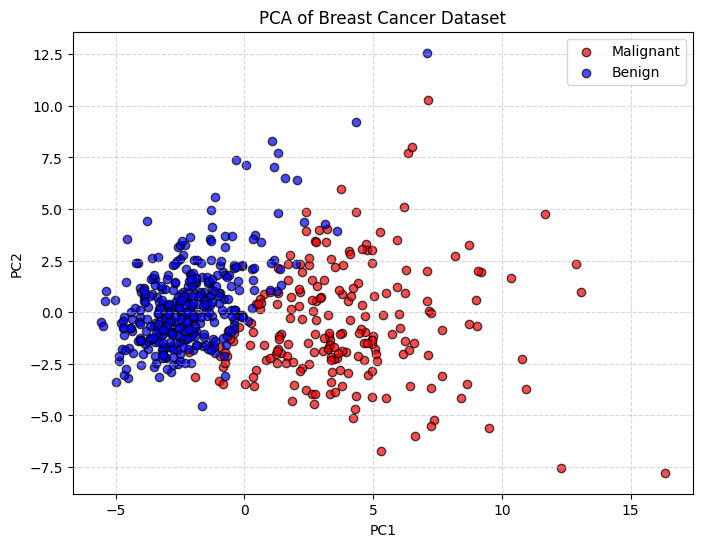

In [ ]:
# 3. Create a 2D scatter plot
plt.figure(figsize=(8, 6))
target_names = ['Malignant', 'Benign']
# In sklearn's breast cancer dataset: 0 is Malignant, 1 is Benign
for target_val, target_name, color in zip([0, 1], target_names, ['red', 'blue']):
    plt.scatter(X_pca[y == target_val, 0], X_pca[y == target_val, 1],
                color=color, label=target_name, alpha=0.7, edgecolors='k')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Breast Cancer Dataset')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# 4. Train a classifier on the reduced 2-component dataset
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42, stratify=y)

clf = LogisticRegression(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy with 2 Principal Components: {accuracy:.4f}")

Test Accuracy with 2 Principal Components: 0.9474
